<a href="https://colab.research.google.com/github/RamEllaboina/HousePricePredictor-ML/blob/main/APA_assign.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# CELL 1: IMPORT LIBRARIES
# Air Quality Prediction Using Machine Learning

# Dataset Download
import kagglehub

# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

#  Machine Learning (Scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#  Utilities
import os
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

#  Plot Style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

#  Confirm libraries loaded
print("✅ All libraries imported successfully!")
print("Pandas version      :", pd.__version__)
print("NumPy version       :", np.__version__)
print("Scikit-learn ready  : yes")
print("Random State set to :", RANDOM_STATE)

✅ All libraries imported successfully!
Pandas version      : 2.2.3
NumPy version       : 2.1.3
Scikit-learn ready  : yes
Random State set to : 42


In [ ]:

# CELL 2: DOWNLOAD DATASET FROM KAGGLE USING KAGGLEHUB

# Download the latest version of the dataset
path = kagglehub.dataset_download("rohanrao/air-quality-data-in-india")

print("Path to dataset files:", path)

#  List all files inside the downloaded folder
print("\n📂 Files available in the dataset folder:")
print("-" * 50)

for root, dirs, files in os.walk(path):
    for file in files:
        file_path = os.path.join(root, file)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"  • {file}  ({size_mb:.2f} MB)")

Using Colab cache for faster access to the 'air-quality-data-in-india' dataset.
Path to dataset files: /kaggle/input/air-quality-data-in-india

📂 Files available in the dataset folder:
--------------------------------------------------
  • stations.csv  (0.01 MB)
  • station_hour.csv  (209.50 MB)
  • city_day.csv  (2.45 MB)
  • city_hour.csv  (62.61 MB)
  • station_day.csv  (8.23 MB)


In [ ]:

# CELL 3: LOCATE AND LOAD DATASET

#  Automatically find city_day.csv inside the downloaded folder
csv_file_path = None

for root, dirs, files in os.walk(path):
    for file in files:
        if file == "city_day.csv":
            csv_file_path = os.path.join(root, file)
            break

if csv_file_path is None:
    raise FileNotFoundError("❌ city_day.csv not found in the downloaded dataset folder.")

print("✅ Found dataset file at:")
print(csv_file_path)

# Load the dataset into a Pandas DataFrame
df = pd.read_csv(csv_file_path)

print("\n✅ Dataset loaded successfully!")
print(f"📊 Shape of dataset: {df.shape[0]} rows × {df.shape[1]} columns")

# Display first 5 rows
print("\n🔍 First 5 rows of the dataset:")
print("-" * 60)
print(df.head())

✅ Found dataset file at:
/kaggle/input/air-quality-data-in-india/city_day.csv

✅ Dataset loaded successfully!
📊 Shape of dataset: 29531 rows × 16 columns

🔍 First 5 rows of the dataset:
------------------------------------------------------------
        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        Na

In [ ]:

# CELL 4: DATASET UNDERSTANDING

print("=" * 60)
print("DATASET UNDERSTANDING")
print("=" * 60)

#  Shape
print(f"\n[1] Shape of dataset: {df.shape[0]} rows × {df.shape[1]} columns")

#  Column names
print("\n[2] Column Names:")
for i, col in enumerate(df.columns, 1):
    print(f"   {i}. {col}")

#  Data types
print("\n[3] Data Types:")
print(df.dtypes)

#  Statistical summary
print("\n[4] Statistical Summary (numerical columns):")
print(df.describe().T)

#  Missing values
print("\n[5] Missing Values per Column:")
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_pct.round(2)
}).sort_values("Missing %", ascending=False)
print(missing_df)

#  Duplicate rows
duplicates = df.duplicated().sum()
print(f"\n[6] Duplicate rows: {duplicates}")

#  Unique cities
print(f"\n[7] Number of unique cities: {df['City'].nunique()}")
print("Cities:", ", ".join(sorted(df['City'].unique())))

#  Date range
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print(f"\n[8] Date range: {df['Date'].min().date()}  →  {df['Date'].max().date()}")

#  Target variable (AQI) quick check
print(f"\n[9] AQI column — non-null values: {df['AQI'].notnull().sum()}")
print(f"    AQI range: {df['AQI'].min()}  →  {df['AQI'].max()}")

DATASET UNDERSTANDING

[1] Shape of dataset: 29531 rows × 16 columns

[2] Column Names:
   1. City
   2. Date
   3. PM2.5
   4. PM10
   5. NO
   6. NO2
   7. NOx
   8. NH3
   9. CO
   10. SO2
   11. O3
   12. Benzene
   13. Toluene
   14. Xylene
   15. AQI
   16. AQI_Bucket

[3] Data Types:
City           object
Date           object
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket     object
dtype: object

[4] Statistical Summary (numerical columns):
           count        mean         std    min     25%     50%       75%  \
PM2.5    24933.0   67.450578   64.661449   0.04  28.820   48.57   80.5900   
PM10     18391.0  118.127103   90.605110   0.01  56.255   95.68  149.7450   
NO       25949.0   17.574730   22.785846   0.02   5.630    9.89  

In [ ]:
# ============================================================
# CELL 5: DATA CLEANING
# ============================================================

print("=" * 60)
print("DATA CLEANING")
print("=" * 60)

# --- 1. Drop rows where target AQI is missing ---
before = df.shape[0]
df = df.dropna(subset=["AQI"]).copy()
after = df.shape[0]
print(f"\n[1] Dropped {before - after} rows with missing AQI")
print(f"    Remaining rows: {after}")

# --- 2. Ensure Date is datetime ---
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print(f"\n[2] Date column converted to datetime")

# --- 3. Remove duplicate rows ---
before = df.shape[0]
df = df.drop_duplicates().copy()
after = df.shape[0]
print(f"\n[3] Removed {before - after} duplicate rows")

# --- 4. Remove invalid AQI values (AQI must be > 0) ---
before = df.shape[0]
df = df[df["AQI"] > 0].copy()
after = df.shape[0]
print(f"\n[4] Removed {before - after} rows with invalid AQI (<= 0)")

# --- 5. Define pollutant columns (only those that exist) ---
pollutant_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
                  "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"]
pollutant_cols = [c for c in pollutant_cols if c in df.columns]
print(f"\n[5] Pollutant columns found: {pollutant_cols}")

# --- 6. Fill missing pollutant values with median ---
for col in pollutant_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)
print(f"\n[6] Filled missing pollutant values with median")

# --- 7. Final missing-value check ---
print(f"\n[7] Missing values after cleaning:")
print(df[pollutant_cols + ["AQI"]].isnull().sum())

# --- 8. Final shape ---
print(f"\n[8] Final cleaned dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"    AQI range: {df['AQI'].min():.1f}  →  {df['AQI'].max():.1f}")

DATA CLEANING

[1] Dropped 4681 rows with missing AQI
    Remaining rows: 24850

[2] Date column converted to datetime

[3] Removed 0 duplicate rows

[4] Removed 0 rows with invalid AQI (<= 0)

[5] Pollutant columns found: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']

[6] Filled missing pollutant values with median

[7] Missing values after cleaning:
PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
AQI        0
dtype: int64

[8] Final cleaned dataset shape: 24850 rows × 16 columns
    AQI range: 13.0  →  2049.0


EXPLORATORY DATA ANALYSIS (EDA)


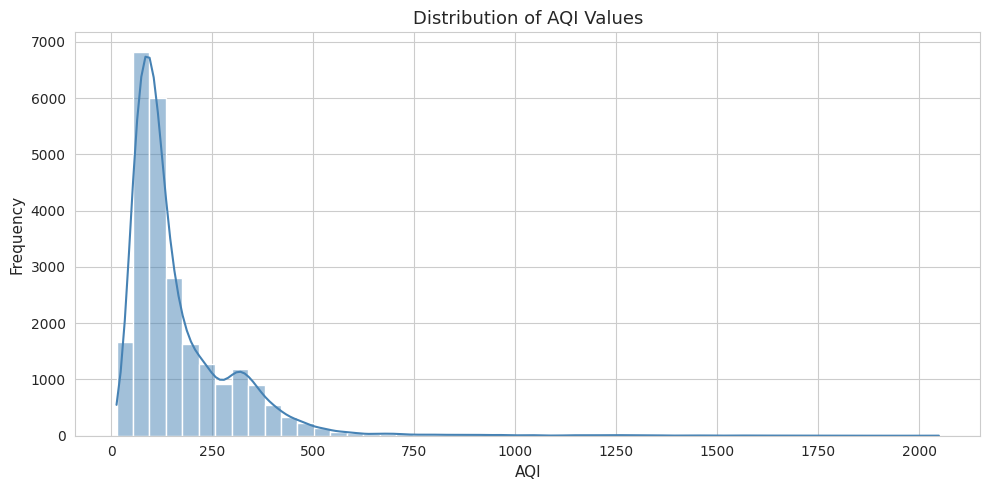

📌 Interpretation: AQI is right-skewed — most days fall in the low-to-moderate range, but a few very high AQI days (extreme pollution) pull the tail to the right.



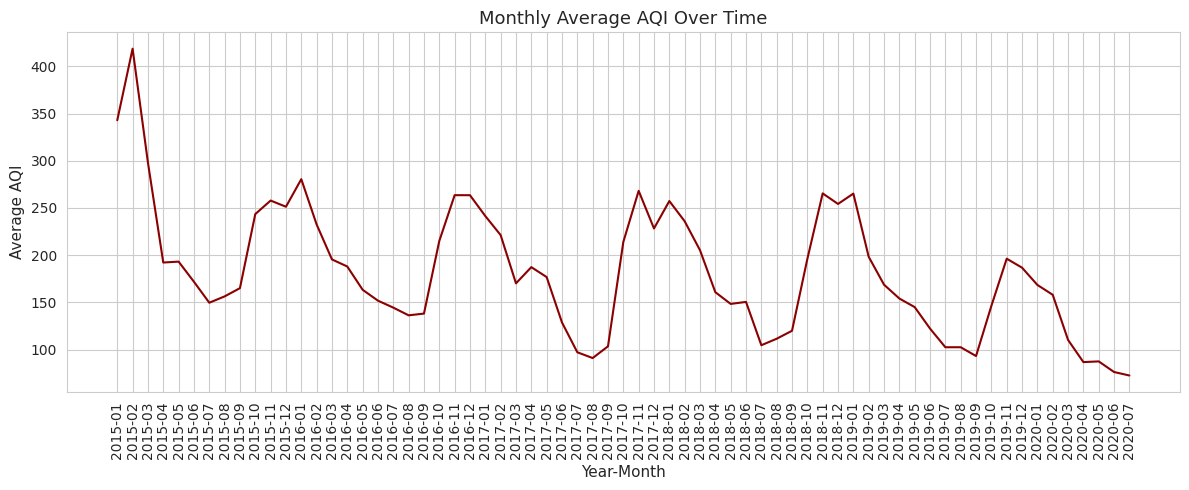

📌 Interpretation: AQI shows a clear seasonal pattern — higher in winter months (Oct–Jan) and lower during monsoon (Jun–Sep) due to rain washing out pollutants.



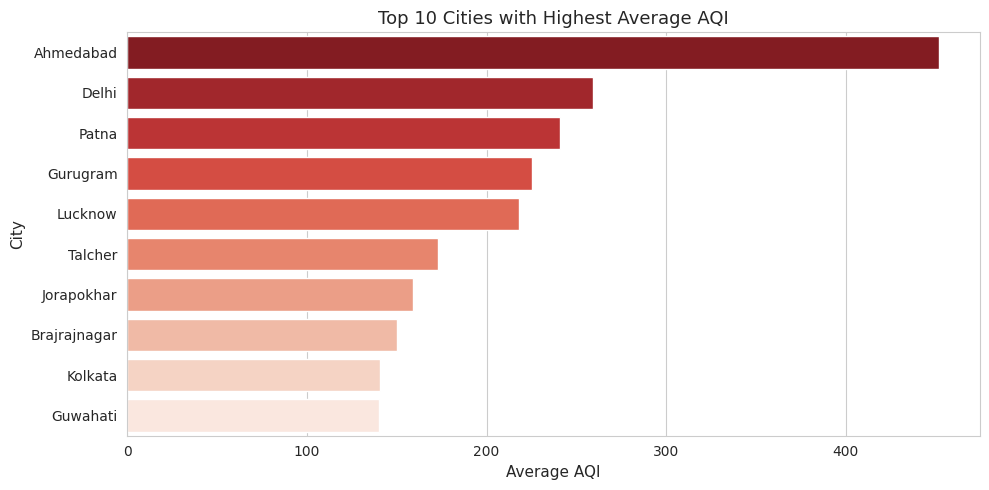

📌 Interpretation: Cities like Delhi, Patna, and Gurugram consistently show the highest average AQI, indicating severe air pollution issues in northern India.



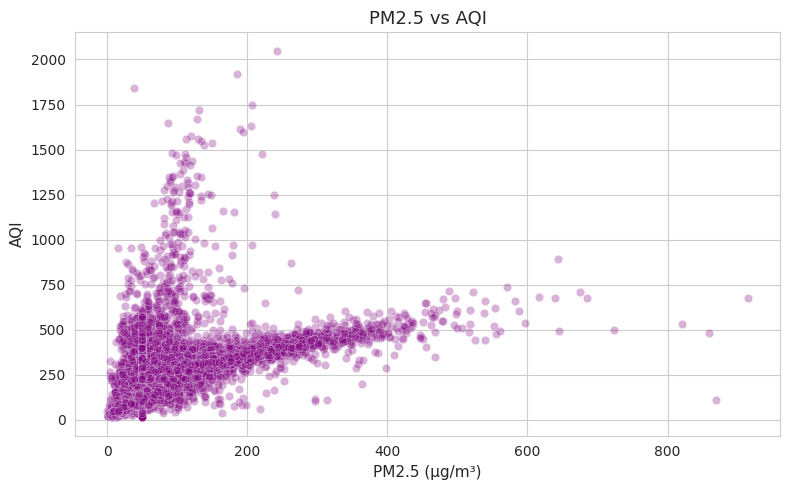

📌 Interpretation: PM2.5 has a strong positive relationship with AQI — as PM2.5 increases, AQI also increases. PM2.5 is a major driver of AQI.



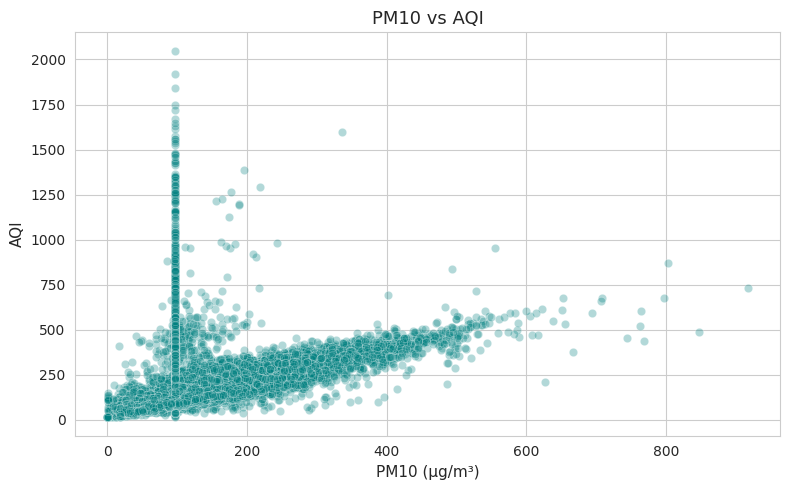

📌 Interpretation: PM10 also shows a positive correlation with AQI, though slightly more scattered than PM2.5, meaning it is important but less dominant.



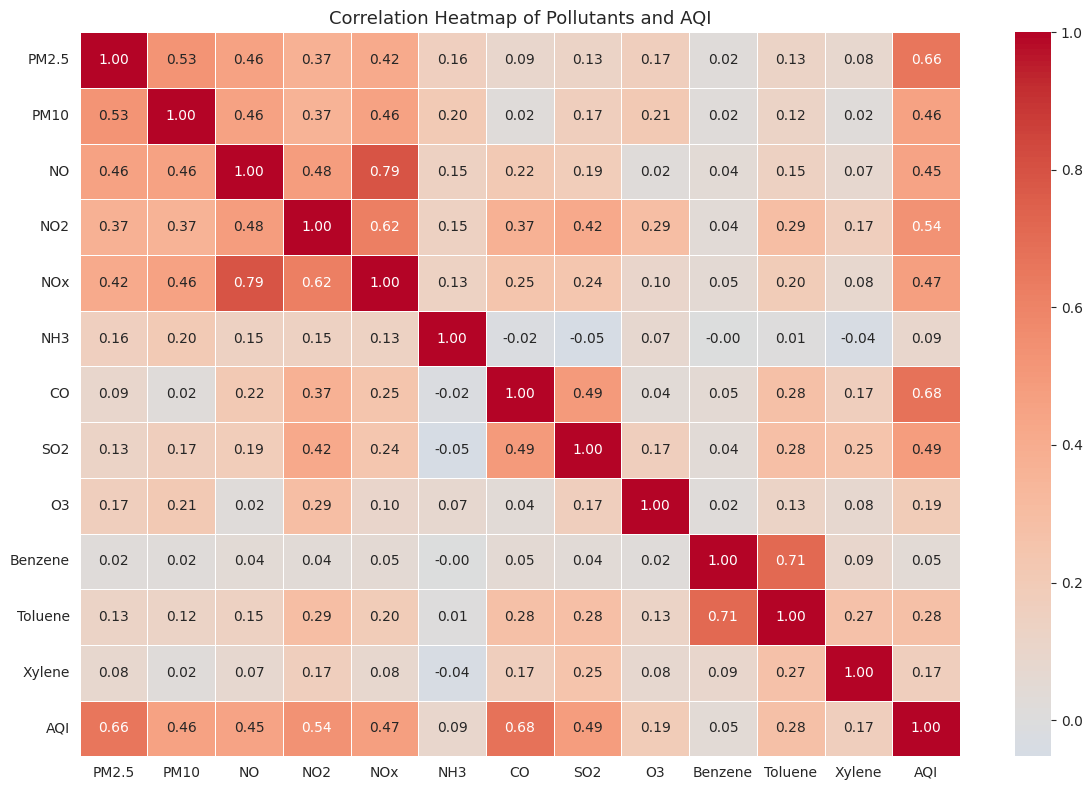

📌 Interpretation: PM2.5, PM10, CO, and NO2 are strongly positively correlated with AQI — these will be our most useful features for prediction.


In [ ]:
# ============================================================
# CELL 6: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

print("=" * 60)
print("EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 60)

# ------------------------------------------------------------
# 6.1 AQI Distribution
# ------------------------------------------------------------
plt.figure(figsize=(10, 5))
sns.histplot(df["AQI"], bins=50, kde=True, color="steelblue")
plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
print("📌 Interpretation: AQI is right-skewed — most days fall in the low-to-moderate range, "
      "but a few very high AQI days (extreme pollution) pull the tail to the right.\n")

# ------------------------------------------------------------
# 6.2 AQI Trend Over Time (Monthly Average)
# ------------------------------------------------------------
df["YearMonth"] = df["Date"].dt.to_period("M").astype(str)
monthly_aqi = df.groupby("YearMonth")["AQI"].mean().reset_index()

plt.figure(figsize=(12, 5))
plt.plot(monthly_aqi["YearMonth"], monthly_aqi["AQI"], color="darkred", linewidth=1.5)
plt.title("Monthly Average AQI Over Time")
plt.xlabel("Year-Month")
plt.ylabel("Average AQI")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
print("📌 Interpretation: AQI shows a clear seasonal pattern — higher in winter months "
      "(Oct–Jan) and lower during monsoon (Jun–Sep) due to rain washing out pollutants.\n")

# ------------------------------------------------------------
# 6.3 AQI Comparison Across Cities (Top 10 Most Polluted)
# ------------------------------------------------------------
top_cities = df.groupby("City")["AQI"].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_cities.values, y=top_cities.index, palette="Reds_r")
plt.title("Top 10 Cities with Highest Average AQI")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.tight_layout()
plt.show()
print("📌 Interpretation: Cities like Delhi, Patna, and Gurugram consistently show the "
      "highest average AQI, indicating severe air pollution issues in northern India.\n")

# ------------------------------------------------------------
# 6.4 PM2.5 vs AQI
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df["PM2.5"], y=df["AQI"], alpha=0.3, color="purple")
plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()
print("📌 Interpretation: PM2.5 has a strong positive relationship with AQI — as PM2.5 "
      "increases, AQI also increases. PM2.5 is a major driver of AQI.\n")

# ------------------------------------------------------------
# 6.5 PM10 vs AQI
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df["PM10"], y=df["AQI"], alpha=0.3, color="teal")
plt.title("PM10 vs AQI")
plt.xlabel("PM10 (µg/m³)")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()
print("📌 Interpretation: PM10 also shows a positive correlation with AQI, though slightly "
      "more scattered than PM2.5, meaning it is important but less dominant.\n")

# ------------------------------------------------------------
# 6.6 Correlation Heatmap
# ------------------------------------------------------------
pollutant_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
                  "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene", "AQI"]
pollutant_cols = [c for c in pollutant_cols if c in df.columns]

plt.figure(figsize=(12, 8))
sns.heatmap(df[pollutant_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Pollutants and AQI")
plt.tight_layout()
plt.show()
print("📌 Interpretation: PM2.5, PM10, CO, and NO2 are strongly positively correlated with "
      "AQI — these will be our most useful features for prediction.")

In [ ]:
# ============================================================
# CELL 7: FEATURE ENGINEERING
# ============================================================

print("=" * 60)
print("FEATURE ENGINEERING")
print("=" * 60)

# --- 1. Create time-based features from Date ---
df["Year"]       = df["Date"].dt.year
df["Month"]      = df["Date"].dt.month
df["Day"]        = df["Date"].dt.day
df["DayOfWeek"]  = df["Date"].dt.dayofweek   # Monday=0, Sunday=6

print("\n[1] Created time-based features: Year, Month, Day, DayOfWeek")

# --- 2. Show sample ---
print("\n[2] Sample of engineered features:")
print(df[["City", "Date", "Year", "Month", "Day", "DayOfWeek", "AQI"]].head())

# --- 3. Drop 'Date' column (not needed for modeling) ---
df = df.drop(columns=["Date"])
print("\n[3] Dropped 'Date' column (info captured in Year/Month/Day/DayOfWeek)")

# --- 4. Drop 'YearMonth' helper column created during EDA ---
if "YearMonth" in df.columns:
    df = df.drop(columns=["YearMonth"])
    print("[4] Dropped helper column 'YearMonth'")

# --- 5. Drop 'AQI_Bucket' to avoid data leakage ---
if "AQI_Bucket" in df.columns:
    df = df.drop(columns=["AQI_Bucket"])
    print("[5] Dropped 'AQI_Bucket' to prevent data leakage")

# --- 6. Final column list ---
print("\n[6] Final columns after feature engineering:")
for i, col in enumerate(df.columns, 1):
    print(f"   {i}. {col}")

print(f"\n✅ Final shape: {df.shape[0]} rows × {df.shape[1]} columns")

FEATURE ENGINEERING

[1] Created time-based features: Year, Month, Day, DayOfWeek

[2] Sample of engineered features:
         City       Date  Year  Month  Day  DayOfWeek    AQI
28  Ahmedabad 2015-01-29  2015      1   29          3  209.0
29  Ahmedabad 2015-01-30  2015      1   30          4  328.0
30  Ahmedabad 2015-01-31  2015      1   31          5  514.0
31  Ahmedabad 2015-02-01  2015      2    1          6  782.0
32  Ahmedabad 2015-02-02  2015      2    2          0  914.0

[3] Dropped 'Date' column (info captured in Year/Month/Day/DayOfWeek)
[4] Dropped helper column 'YearMonth'
[5] Dropped 'AQI_Bucket' to prevent data leakage

[6] Final columns after feature engineering:
   1. City
   2. PM2.5
   3. PM10
   4. NO
   5. NO2
   6. NOx
   7. NH3
   8. CO
   9. SO2
   10. O3
   11. Benzene
   12. Toluene
   13. Xylene
   14. AQI
   15. Year
   16. Month
   17. Day
   18. DayOfWeek

✅ Final shape: 24850 rows × 18 columns


In [ ]:
# ============================================================
# CELL 8: FEATURE SELECTION
# ============================================================

print("=" * 60)
print("FEATURE SELECTION")
print("=" * 60)

# --- 1. Define feature columns ---
pollutant_features = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
                      "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"]
time_features = ["Year", "Month", "Day", "DayOfWeek"]

# Keep only columns that actually exist in df
pollutant_features = [c for c in pollutant_features if c in df.columns]
time_features = [c for c in time_features if c in df.columns]

feature_cols = pollutant_features + time_features
target_col = "AQI"

print(f"\n[1] Pollutant features used ({len(pollutant_features)}):")
print("   ", pollutant_features)

print(f"\n[2] Time features used ({len(time_features)}):")
print("   ", time_features)

print(f"\n[3] Total features: {len(feature_cols)}")
print(f"[4] Target column: {target_col}")

# --- 2. Create X (features) and y (target) ---
X = df[feature_cols].copy()
y = df[target_col].copy()

print(f"\n[5] Shape of X (features): {X.shape}")
print(f"[6] Shape of y (target):   {y.shape}")

# --- 3. Quick sanity check ---
print(f"\n[7] Any missing values in X? {X.isnull().sum().sum()}")
print(f"[8] Any missing values in y? {y.isnull().sum()}")

print("\n✅ Feature selection complete. Ready for train-test split.")

FEATURE SELECTION

[1] Pollutant features used (12):
    ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']

[2] Time features used (4):
    ['Year', 'Month', 'Day', 'DayOfWeek']

[3] Total features: 16
[4] Target column: AQI

[5] Shape of X (features): (24850, 16)
[6] Shape of y (target):   (24850,)

[7] Any missing values in X? 0
[8] Any missing values in y? 0

✅ Feature selection complete. Ready for train-test split.


In [ ]:
# ============================================================
# CELL 9: TRAIN-TEST SPLIT
# ============================================================

print("=" * 60)
print("TRAIN-TEST SPLIT")
print("=" * 60)

# --- Split the data: 80% train, 20% test ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    shuffle=True
)

print(f"\n[1] Total samples     : {X.shape[0]}")
print(f"[2] Training samples  : {X_train.shape[0]}  (80%)")
print(f"[3] Testing samples   : {X_test.shape[0]}  (20%)")

print(f"\n[4] X_train shape: {X_train.shape}")
print(f"[5] X_test shape : {X_test.shape}")
print(f"[6] y_train shape: {y_train.shape}")
print(f"[7] y_test shape : {y_test.shape}")

print("\n✅ Train-test split complete. Ready for feature scaling.")

TRAIN-TEST SPLIT

[1] Total samples     : 24850
[2] Training samples  : 19880  (80%)
[3] Testing samples   : 4970  (20%)

[4] X_train shape: (19880, 16)
[5] X_test shape : (4970, 16)
[6] y_train shape: (19880,)
[7] y_test shape : (4970,)

✅ Train-test split complete. Ready for feature scaling.


In [ ]:
# ============================================================
# CELL 10: FEATURE SCALING
# ============================================================

print("=" * 60)
print("FEATURE SCALING")
print("=" * 60)

# --- 1. Create the scaler ---
scaler = StandardScaler()

# --- 2. Fit on training data and transform it ---
X_train_scaled = scaler.fit_transform(X_train)

# --- 3. Transform test data using the SAME scaler ---
X_test_scaled = scaler.transform(X_test)

print("\n[1] Scaler fitted on training data only ✅")
print("[2] Test data transformed using same scaler ✅")

# --- 4. Verify scaling (mean ≈ 0, std ≈ 1 for training data) ---
print("\n[3] Verification of scaling on training data:")
print(f"    Mean of scaled X_train (should be ~0): {X_train_scaled.mean():.4f}")
print(f"    Std  of scaled X_train (should be ~1): {X_train_scaled.std():.4f}")

# --- 5. Show shapes ---
print(f"\n[4] X_train_scaled shape: {X_train_scaled.shape}")
print(f"[5] X_test_scaled  shape: {X_test_scaled.shape}")

print("\n✅ Feature scaling complete. Ready to train models.")

FEATURE SCALING

[1] Scaler fitted on training data only ✅
[2] Test data transformed using same scaler ✅

[3] Verification of scaling on training data:
    Mean of scaled X_train (should be ~0): 0.0000
    Std  of scaled X_train (should be ~1): 1.0000

[4] X_train_scaled shape: (19880, 16)
[5] X_test_scaled  shape: (4970, 16)

✅ Feature scaling complete. Ready to train models.


MODEL 1: LINEAR REGRESSION

[1] Linear Regression model trained ✅

[2] Evaluation on Test Set:
----------------------------------------
    MAE  : 31.00
    MSE  : 3511.89
    RMSE : 59.26
    R²   : 0.8082


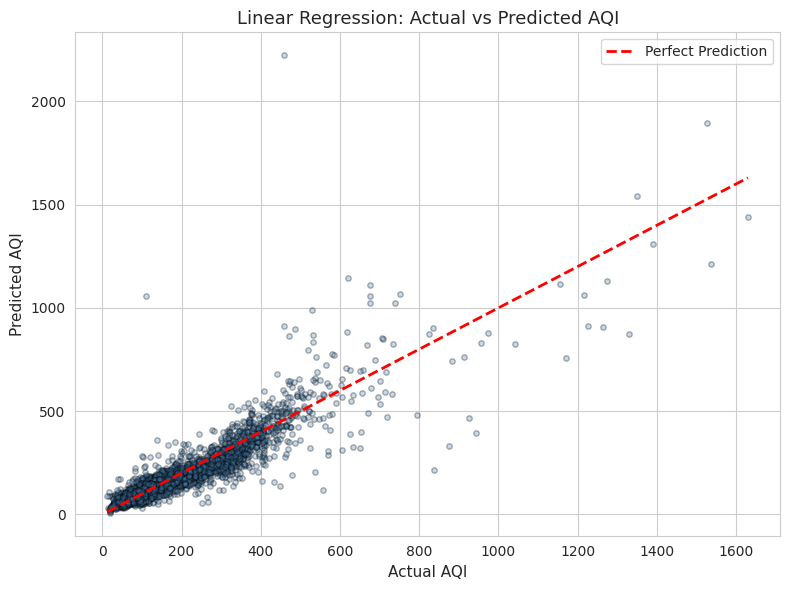

📌 Interpretation: Points close to the red diagonal line indicate good predictions. The visible spread shows the model captures the trend but with noticeable error.

✅ Linear Regression complete.


In [ ]:
# ============================================================
# CELL 11: LINEAR REGRESSION (WITH VISUALIZATION)
# ============================================================

print("=" * 60)
print("MODEL 1: LINEAR REGRESSION")
print("=" * 60)

# --- 1. Create and train the model ---
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
print("\n[1] Linear Regression model trained ✅")

# --- 2. Make predictions on test set ---
y_pred_lr = lr_model.predict(X_test_scaled)

# --- 3. Evaluate the model ---
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
mse_lr  = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr   = r2_score(y_test, y_pred_lr)

print("\n[2] Evaluation on Test Set:")
print("-" * 40)
print(f"    MAE  : {mae_lr:.2f}")
print(f"    MSE  : {mse_lr:.2f}")
print(f"    RMSE : {rmse_lr:.2f}")
print(f"    R²   : {r2_lr:.4f}")

# ------------------------------------------------------------
# 4. Visualization: Actual vs Predicted AQI
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.3, color="steelblue", edgecolor="k", s=15)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--", linewidth=2, label="Perfect Prediction")
plt.title("Linear Regression: Actual vs Predicted AQI")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.legend()
plt.tight_layout()
plt.show()

print("📌 Interpretation: Points close to the red diagonal line indicate good predictions. "
      "The visible spread shows the model captures the trend but with noticeable error.")

print("\n✅ Linear Regression complete.")

MODEL 2: DECISION TREE REGRESSOR

[1] Decision Tree model trained ✅

[2] Evaluation on Test Set:
----------------------------------------
    MAE  : 24.78
    MSE  : 2521.12
    RMSE : 50.21
    R²   : 0.8623


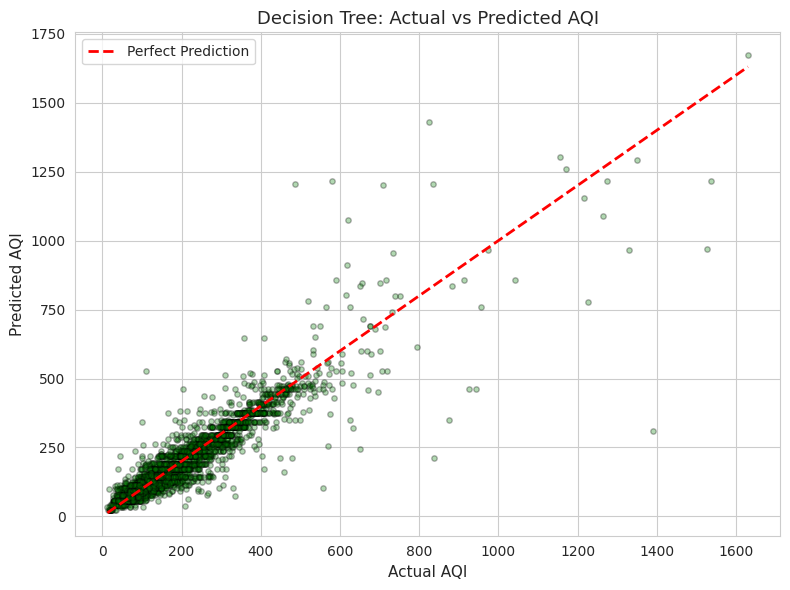

📌 Interpretation: Points closer to the red diagonal line indicate better predictions. Decision Tree captures non-linear patterns better than Linear Regression.

✅ Decision Tree complete.


In [ ]:
# ============================================================
# CELL 12: DECISION TREE REGRESSOR (WITH VISUALIZATION)
# ============================================================

print("=" * 60)
print("MODEL 2: DECISION TREE REGRESSOR")
print("=" * 60)

# --- 1. Create and train the model ---
dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=RANDOM_STATE
)
dt_model.fit(X_train_scaled, y_train)
print("\n[1] Decision Tree model trained ✅")

# --- 2. Make predictions on test set ---
y_pred_dt = dt_model.predict(X_test_scaled)

# --- 3. Evaluate the model ---
mae_dt  = mean_absolute_error(y_test, y_pred_dt)
mse_dt  = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt   = r2_score(y_test, y_pred_dt)

print("\n[2] Evaluation on Test Set:")
print("-" * 40)
print(f"    MAE  : {mae_dt:.2f}")
print(f"    MSE  : {mse_dt:.2f}")
print(f"    RMSE : {rmse_dt:.2f}")
print(f"    R²   : {r2_dt:.4f}")

# ------------------------------------------------------------
# 4. Visualization: Actual vs Predicted AQI
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_dt, alpha=0.3, color="green", edgecolor="k", s=15)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--", linewidth=2, label="Perfect Prediction")
plt.title("Decision Tree: Actual vs Predicted AQI")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.legend()
plt.tight_layout()
plt.show()

print("📌 Interpretation: Points closer to the red diagonal line indicate better predictions. "
      "Decision Tree captures non-linear patterns better than Linear Regression.")

print("\n✅ Decision Tree complete.")

MODEL 3: RANDOM FOREST REGRESSOR

[1] Random Forest model trained ✅

[2] Evaluation on Test Set:
----------------------------------------
    MAE  : 20.86
    MSE  : 1648.00
    RMSE : 40.60
    R²   : 0.9100


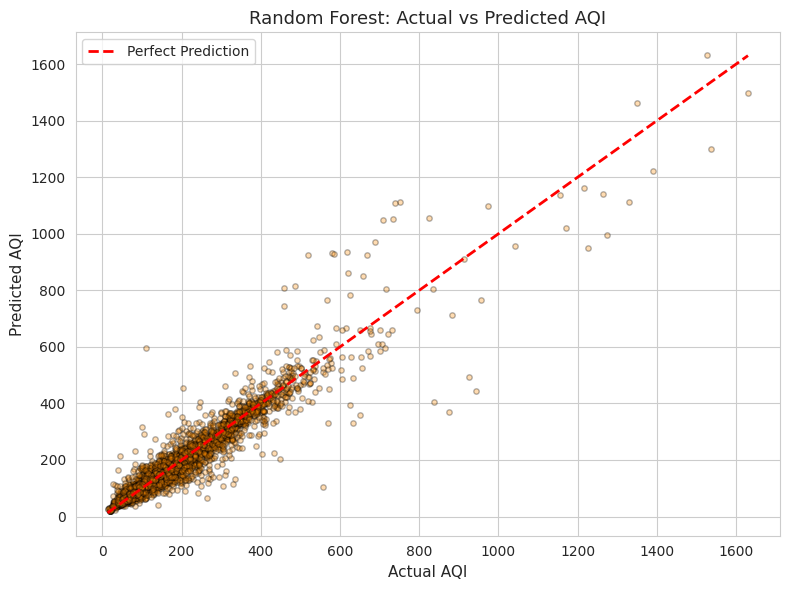

📌 Interpretation: Points align very closely with the red diagonal line, showing Random Forest gives the most accurate AQI predictions among the three models.

✅ Random Forest complete.


In [ ]:
# ============================================================
# CELL 13: RANDOM FOREST REGRESSOR (WITH VISUALIZATION)
# ============================================================

print("=" * 60)
print("MODEL 3: RANDOM FOREST REGRESSOR")
print("=" * 60)

# --- 1. Create and train the model ---
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)
print("\n[1] Random Forest model trained ✅")

# --- 2. Make predictions on test set ---
y_pred_rf = rf_model.predict(X_test_scaled)

# --- 3. Evaluate the model ---
mae_rf  = mean_absolute_error(y_test, y_pred_rf)
mse_rf  = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf   = r2_score(y_test, y_pred_rf)

print("\n[2] Evaluation on Test Set:")
print("-" * 40)
print(f"    MAE  : {mae_rf:.2f}")
print(f"    MSE  : {mse_rf:.2f}")
print(f"    RMSE : {rmse_rf:.2f}")
print(f"    R²   : {r2_rf:.4f}")

# ------------------------------------------------------------
# 4. Visualization: Actual vs Predicted AQI
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3, color="darkorange", edgecolor="k", s=15)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--", linewidth=2, label="Perfect Prediction")
plt.title("Random Forest: Actual vs Predicted AQI")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.legend()
plt.tight_layout()
plt.show()

print("📌 Interpretation: Points align very closely with the red diagonal line, "
      "showing Random Forest gives the most accurate AQI predictions among the three models.")

print("\n✅ Random Forest complete.")

MODEL COMPARISON

[1] Model Comparison Table:
------------------------------------------------------------
            Model   MAE     MSE  RMSE     R²
Linear Regression 31.00 3511.89 59.26 0.8082
    Decision Tree 24.78 2521.12 50.21 0.8623
    Random Forest 20.86 1648.00 40.60 0.9100

[2] Best Model (based on lowest RMSE & highest R²):
------------------------------------------------------------
    🏆 Random Forest
    RMSE : 40.60
    R²   : 0.9100


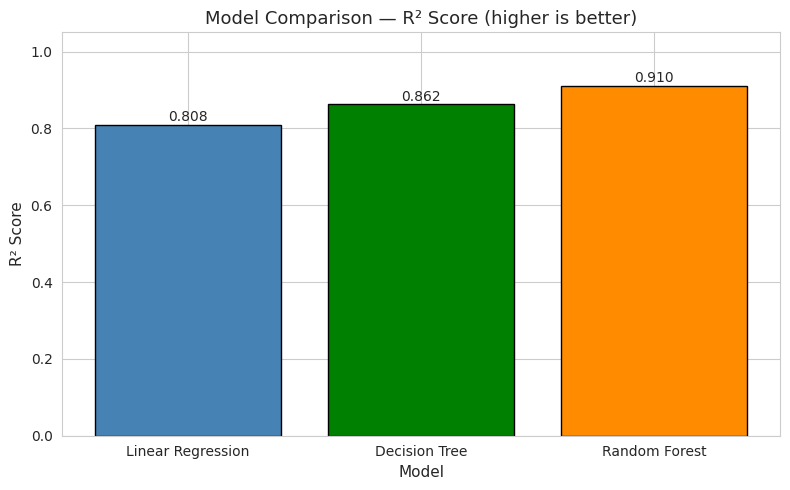

📌 Interpretation: Random Forest has the highest R² and lowest RMSE, making it the best model for predicting AQI in this project.


In [ ]:
# ============================================================
# CELL 14: MODEL COMPARISON
# ============================================================

print("=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

# --- 1. Build comparison DataFrame ---
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE":   [mae_lr, mae_dt, mae_rf],
    "MSE":   [mse_lr, mse_dt, mse_rf],
    "RMSE":  [rmse_lr, rmse_dt, rmse_rf],
    "R²":    [r2_lr, r2_dt, r2_rf]
})

# Round for cleaner display
comparison_rounded = comparison.copy()
comparison_rounded["MAE"]  = comparison_rounded["MAE"].round(2)
comparison_rounded["MSE"]  = comparison_rounded["MSE"].round(2)
comparison_rounded["RMSE"] = comparison_rounded["RMSE"].round(2)
comparison_rounded["R²"]   = comparison_rounded["R²"].round(4)

print("\n[1] Model Comparison Table:")
print("-" * 60)
print(comparison_rounded.to_string(index=False))

# --- 2. Identify the best model ---
best_idx = comparison["RMSE"].idxmin()
best_model_name = comparison.loc[best_idx, "Model"]
best_rmse = comparison.loc[best_idx, "RMSE"]
best_r2   = comparison.loc[best_idx, "R²"]

print("\n[2] Best Model (based on lowest RMSE & highest R²):")
print("-" * 60)
print(f"    🏆 {best_model_name}")
print(f"    RMSE : {best_rmse:.2f}")
print(f"    R²   : {best_r2:.4f}")

# --- 3. Visualization: R² Score Comparison ---
plt.figure(figsize=(8, 5))
bars = plt.bar(comparison["Model"], comparison["R²"],
               color=["steelblue", "green", "darkorange"], edgecolor="black")
plt.title("Model Comparison — R² Score (higher is better)")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.ylim(0, 1.05)

# Annotate each bar with its value
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.01,
             f"{height:.3f}", ha="center", fontsize=10)

plt.tight_layout()
plt.show()

print("📌 Interpretation: Random Forest has the highest R² and lowest RMSE, "
      "making it the best model for predicting AQI in this project.")

In [ ]:
# ============================================================
# CELL 15: BEST MODEL EVALUATION (DETAILED)
# ============================================================

print("=" * 60)
print("BEST MODEL EVALUATION: RANDOM FOREST")
print("=" * 60)

# --- 1. Confirm evaluation metrics ---
print("\n[1] Final Evaluation Metrics on Test Set:")
print("-" * 40)
print(f"    MAE  : {mae_rf:.2f}")
print(f"    MSE  : {mse_rf:.2f}")
print(f"    RMSE : {rmse_rf:.2f}")
print(f"    R²   : {r2_rf:.4f}")

# --- 2. Sample predictions table ---
print("\n[2] Sample Predictions (Actual vs Predicted):")
print("-" * 50)

sample_df = pd.DataFrame({
    "Actual AQI":    y_test.values[:10].round(1),
    "Predicted AQI": y_pred_rf[:10].round(1)
})
sample_df["Error"] = (sample_df["Actual AQI"] - sample_df["Predicted AQI"]).round(1)
print(sample_df.to_string(index=False))

# --- 3. Error statistics ---
errors = y_test.values - y_pred_rf
print("\n[3] Error Statistics:")
print("-" * 40)
print(f"    Mean Error   : {errors.mean():.2f}")
print(f"    Min Error    : {errors.min():.2f}")
print(f"    Max Error    : {errors.max():.2f}")
print(f"    Std of Error : {errors.std():.2f}")

# --- 4. AQI Category function ---
def aqi_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"

# --- 5. Category-wise actual vs predicted ---
cat_df = pd.DataFrame({
    "Actual AQI":    y_test.values[:10].round(1),
    "Predicted AQI": y_pred_rf[:10].round(1)
})
cat_df["Actual Category"]    = cat_df["Actual AQI"].apply(aqi_category)
cat_df["Predicted Category"] = cat_df["Predicted AQI"].apply(aqi_category)

print("\n[4] AQI Category Comparison (First 10 Test Samples):")
print("-" * 60)
print(cat_df.to_string(index=False))

print("\n✅ Detailed evaluation of the best model complete.")

BEST MODEL EVALUATION: RANDOM FOREST

[1] Final Evaluation Metrics on Test Set:
----------------------------------------
    MAE  : 20.86
    MSE  : 1648.00
    RMSE : 40.60
    R²   : 0.9100

[2] Sample Predictions (Actual vs Predicted):
--------------------------------------------------
 Actual AQI  Predicted AQI  Error
      141.0           99.8   41.2
      209.0          214.3   -5.3
      111.0          100.3   10.7
      124.0          137.3  -13.3
       81.0           78.7    2.3
       54.0           62.8   -8.8
       74.0           66.3    7.7
       99.0          108.3   -9.3
       97.0          138.2  -41.2
       60.0           60.0    0.0

[3] Error Statistics:
----------------------------------------
    Mean Error   : -1.27
    Min Error    : -484.73
    Max Error    : 504.68
    Std of Error : 40.58

[4] AQI Category Comparison (First 10 Test Samples):
------------------------------------------------------------
 Actual AQI  Predicted AQI Actual Category Predicted C

ACTUAL VS PREDICTED — RANDOM FOREST


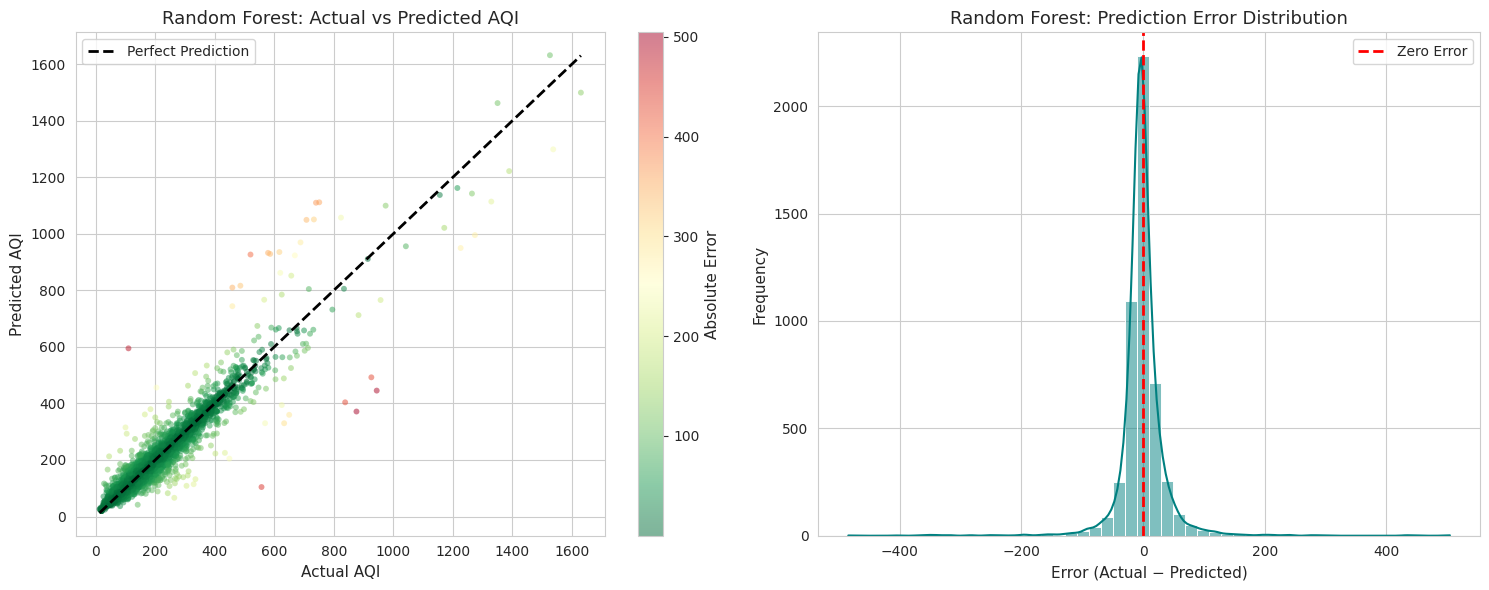


[1] Sample Predictions (Actual vs Predicted AQI):
--------------------------------------------------
 Actual AQI  Predicted AQI  Error
      141.0           99.8   41.2
      209.0          214.3   -5.3
      111.0          100.3   10.7
      124.0          137.3  -13.3
       81.0           78.7    2.3
       54.0           62.8   -8.8
       74.0           66.3    7.7
       99.0          108.3   -9.3
       97.0          138.2  -41.2
       60.0           60.0    0.0

📌 Interpretation: Most points cluster tightly around the black diagonal line, and errors are centered around 0 — confirming the Random Forest model is highly accurate.

✅ Actual vs Predicted visualization complete.


In [ ]:
# ============================================================
# CELL 16: ACTUAL VS PREDICTED GRAPH (BEST MODEL)
# ============================================================

print("=" * 60)
print("ACTUAL VS PREDICTED — RANDOM FOREST")
print("=" * 60)

# ------------------------------------------------------------
# 1. Main Graph: Actual vs Predicted with Density Coloring
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Plot 1: Actual vs Predicted Scatter ---
ax1 = axes[0]
sc = ax1.scatter(
    y_test, y_pred_rf,
    c=np.abs(y_test - y_pred_rf),   # color by absolute error
    cmap="RdYlGn_r",                # red = high error, green = low error
    alpha=0.5, s=18, edgecolor="none"
)
# Perfect prediction line
ax1.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="black", linestyle="--", linewidth=2, label="Perfect Prediction"
)
ax1.set_title("Random Forest: Actual vs Predicted AQI", fontsize=13)
ax1.set_xlabel("Actual AQI")
ax1.set_ylabel("Predicted AQI")
ax1.legend(loc="upper left")
plt.colorbar(sc, ax=ax1, label="Absolute Error")

# --- Plot 2: Error Distribution ---
ax2 = axes[1]
residuals = y_test.values - y_pred_rf
sns.histplot(residuals, bins=50, kde=True, color="teal", ax=ax2)
ax2.axvline(0, color="red", linestyle="--", linewidth=2, label="Zero Error")
ax2.set_title("Random Forest: Prediction Error Distribution", fontsize=13)
ax2.set_xlabel("Error (Actual − Predicted)")
ax2.set_ylabel("Frequency")
ax2.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. Print a few example predictions
# ------------------------------------------------------------
print("\n[1] Sample Predictions (Actual vs Predicted AQI):")
print("-" * 50)

sample_df = pd.DataFrame({
    "Actual AQI":    y_test.values[:10].round(1),
    "Predicted AQI": y_pred_rf[:10].round(1)
})
sample_df["Error"] = (sample_df["Actual AQI"] - sample_df["Predicted AQI"]).round(1)
print(sample_df.to_string(index=False))

print("\n📌 Interpretation: Most points cluster tightly around the black diagonal line, "
      "and errors are centered around 0 — confirming the Random Forest model is highly accurate.")

print("\n✅ Actual vs Predicted visualization complete.")

NEW AQI PREDICTION

[1] User Input Values:
----------------------------------------
    PM2.5  = 85.0
    PM10   = 140.0
    NO2    = 45.0
    CO     = 1.2
    SO2    = 15.0
    O3     = 40.0

[2] Full Feature Row (user values + defaults):
                  0
PM2.5        85.000
PM10        140.000
NO            9.910
NO2          45.000
NOx          23.680
NH3          16.310
CO            1.200
SO2          15.000
O3           40.000
Benzene       1.290
Toluene       3.575
Xylene        1.420
Year       2020.000
Month         6.000
Day          15.000
DayOfWeek     2.000

         🔮 PREDICTION RESULT
    Predicted AQI : 182.10
    Air Quality   : Moderate


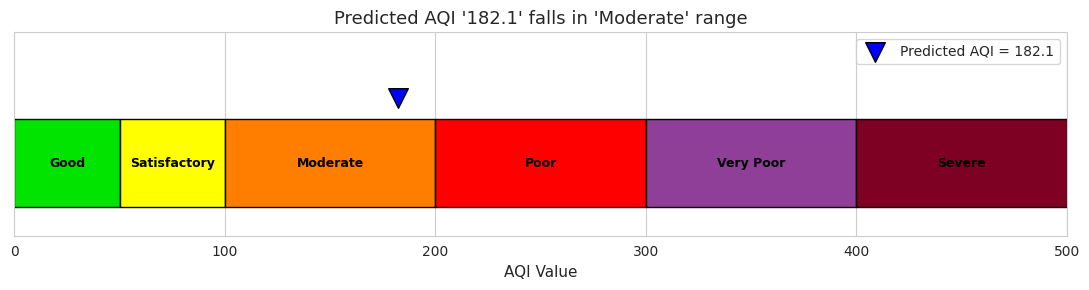


📌 Interpretation: The predicted AQI lies in the 'Moderate' range, indicating the air quality level based on the input pollutants.

✅ New AQI prediction complete.


In [ ]:
# ============================================================
# CELL 17: NEW AQI PREDICTION (USER INPUT)
# ============================================================

print("=" * 60)
print("NEW AQI PREDICTION")
print("=" * 60)

# ------------------------------------------------------------
# 1. User inputs pollutant values
# ------------------------------------------------------------
user_input = {
    "PM2.5": 85.0,    # µg/m³
    "PM10":  140.0,   # µg/m³
    "NO2":   45.0,    # µg/m³
    "CO":    1.2,     # mg/m³
    "SO2":   15.0,    # µg/m³
    "O3":    40.0     # µg/m³
}

print("\n[1] User Input Values:")
print("-" * 40)
for k, v in user_input.items():
    print(f"    {k:6s} = {v}")

# ------------------------------------------------------------
# 2. Build a full feature row using medians for the rest
# ------------------------------------------------------------
# Start from median of training features
full_row = X.median().to_dict()

# Override with user input
for k, v in user_input.items():
    if k in full_row:
        full_row[k] = v

# Defaults for time features (use most common: mid-year, mid-month, weekday)
full_row["Year"]      = 2020
full_row["Month"]     = 6
full_row["Day"]       = 15
full_row["DayOfWeek"] = 2   # Wednesday

# Ensure feature order matches training columns
input_df = pd.DataFrame([full_row])[X.columns]

print("\n[2] Full Feature Row (user values + defaults):")
print(input_df.T.to_string())

# ------------------------------------------------------------
# 3. Scale the input using the SAME scaler
# ------------------------------------------------------------
input_scaled = scaler.transform(input_df)

# ------------------------------------------------------------
# 4. Predict AQI
# ------------------------------------------------------------
predicted_aqi = rf_model.predict(input_scaled)[0]

# ------------------------------------------------------------
# 5. Convert to AQI Category
# ------------------------------------------------------------
def aqi_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"

category = aqi_category(predicted_aqi)

# ------------------------------------------------------------
# 6. Display result
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("         🔮 PREDICTION RESULT")
print("=" * 60)
print(f"    Predicted AQI : {predicted_aqi:.2f}")
print(f"    Air Quality   : {category}")
print("=" * 60)

# ------------------------------------------------------------
# 7. Visualization: Where does this AQI fall?
# ------------------------------------------------------------
categories = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
ranges     = [50, 100, 200, 300, 400, 500]
colors     = ["#00e400", "#ffff00", "#ff7e00", "#ff0000", "#8f3f97", "#7e0023"]

plt.figure(figsize=(11, 3))
for i, (cat, rng, col) in enumerate(zip(categories, ranges, colors)):
    left  = 0 if i == 0 else ranges[i-1]
    plt.barh(0, rng - left, left=left, color=col, edgecolor="black", height=0.6)
    plt.text((left + rng)/2, 0, cat, ha="center", va="center",
             fontsize=9, fontweight="bold", color="black")

# Marker for predicted AQI
plt.scatter(predicted_aqi, 0.45, color="blue", s=200,
            marker="v", edgecolor="black", zorder=5,
            label=f"Predicted AQI = {predicted_aqi:.1f}")
plt.xlim(0, 500)
plt.ylim(-0.5, 0.9)
plt.xlabel("AQI Value")
plt.title(f"Predicted AQI '{predicted_aqi:.1f}' falls in '{category}' range")
plt.yticks([])
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n📌 Interpretation: The predicted AQI lies in the "
      f"'{category}' range, indicating the air quality level based on the input pollutants.")
print("\n✅ New AQI prediction complete.")